# MODIS - create new netcdf files with the rad_total and ref_total Germany

In [ ]:
#!ncdump -h /work/bb1036/b381362/dataset/MYD021KM.A2013122.1140.061.2018046032403.hdf


In [24]:
!python modis_l1b_read_plot.py --path-dataset "/work/bb1036/b381362/dataset" --path-output "/work/bb1036/b381362/output" --task "spectral" 



 ********** MODIS level1B data **********
(31, 58)
0 Latitude
1 Longitude
2 EV_1KM_RefSB
3 EV_1KM_RefSB_Uncert_Indexes
4 EV_1KM_Emissive
5 EV_1KM_Emissive_Uncert_Indexes
6 EV_250_Aggr1km_RefSB
7 EV_250_Aggr1km_RefSB_Uncert_Indexes
8 EV_250_Aggr1km_RefSB_Samples_Used
9 EV_500_Aggr1km_RefSB
10 EV_500_Aggr1km_RefSB_Uncert_Indexes
11 EV_500_Aggr1km_RefSB_Samples_Used
12 Height
13 SensorZenith
14 SensorAzimuth
15 Range
16 SolarZenith
17 SolarAzimuth
18 gflags
19 EV_Band26
20 EV_Band26_Uncert_Indexes
21 Band_250M
22 Band_500M
23 Band_1KM_RefSB
24 Band_1KM_Emissive
25 Noise in Thermal Detectors
26 Change in relative responses of thermal detectors
27 DC Restore Change for Thermal Bands
28 DC Restore Change for Reflective 250m Bands
29 DC Restore Change for Reflective 500m Bands
30 DC Restore Change for Reflective 1km Bands
 ********** Geolocation file **********
(46, 27)
0 Latitude
1 Longitude
2 Scan Offset
3 Track Offset
4 Height Offset
5 Height
6 SensorZenith
7 SensorAzimuth
8 Range
9 SolarZ

# check dataset created

In [25]:
from functions_reading import read_refl_rad_rttov
import matplotlib.pyplot as plt
import xarray as xr

#modis_test_path = "/work/bb1036/b381362/dataset/test_MODIS_Germany_refl_emis_MYD021KM.A2013122.1140.061.2018046032403.nc"
modis_test_path = "/work/bb1036/b381362/dataset/MODIS_T1140_Germany_MYD021KM.A2013122.1140.061.2018046032403.nc"
    
modis_ds = xr.open_dataset(modis_test_path)

modis_ds

<xarray.Dataset>
Dimensions:    (lat: 628, lon: 589, chan: 38)
Coordinates:
  * lat        (lat) float64 47.6 47.61 47.62 47.63 ... 54.46 54.47 54.48 54.5
  * lon        (lon) float64 4.5 4.517 4.534 4.551 ... 14.45 14.46 14.48 14.5
  * chan       (chan) float64 1.0 2.0 3.0 4.0 5.0 ... 32.0 33.0 34.0 35.0 36.0
Data variables:
    ref_total  (chan, lat, lon) float64 ...
    rad_total  (chan, lat, lon) float64 ...
Attributes:
    title:    Germany MODIS

In [26]:
import matplotlib.pyplot as plt
import xarray as xr

ordened_modis_test_path = "/work/bb1036/b381362/dataset/organized_chann_MODIS_T1140_Germany_MYD021KM.A2013122.1140.061.2018046032403.nc"
    
modis_ds = xr.open_dataset(ordened_modis_test_path)

modis_ds


<xarray.Dataset>
Dimensions:    (chan: 36, lat: 628, lon: 589)
Coordinates:
  * chan       (chan) float64 1.0 2.0 3.0 4.0 5.0 ... 32.0 33.0 34.0 35.0 36.0
  * lat        (lat) float64 47.6 47.61 47.62 47.63 ... 54.46 54.47 54.48 54.5
  * lon        (lon) float64 4.5 4.517 4.534 4.551 ... 14.45 14.46 14.48 14.5
Data variables:
    ref_total  (chan, lat, lon) float64 ...
    rad_total  (chan, lat, lon) float64 ...
Attributes:
    title:    Germany MODIS

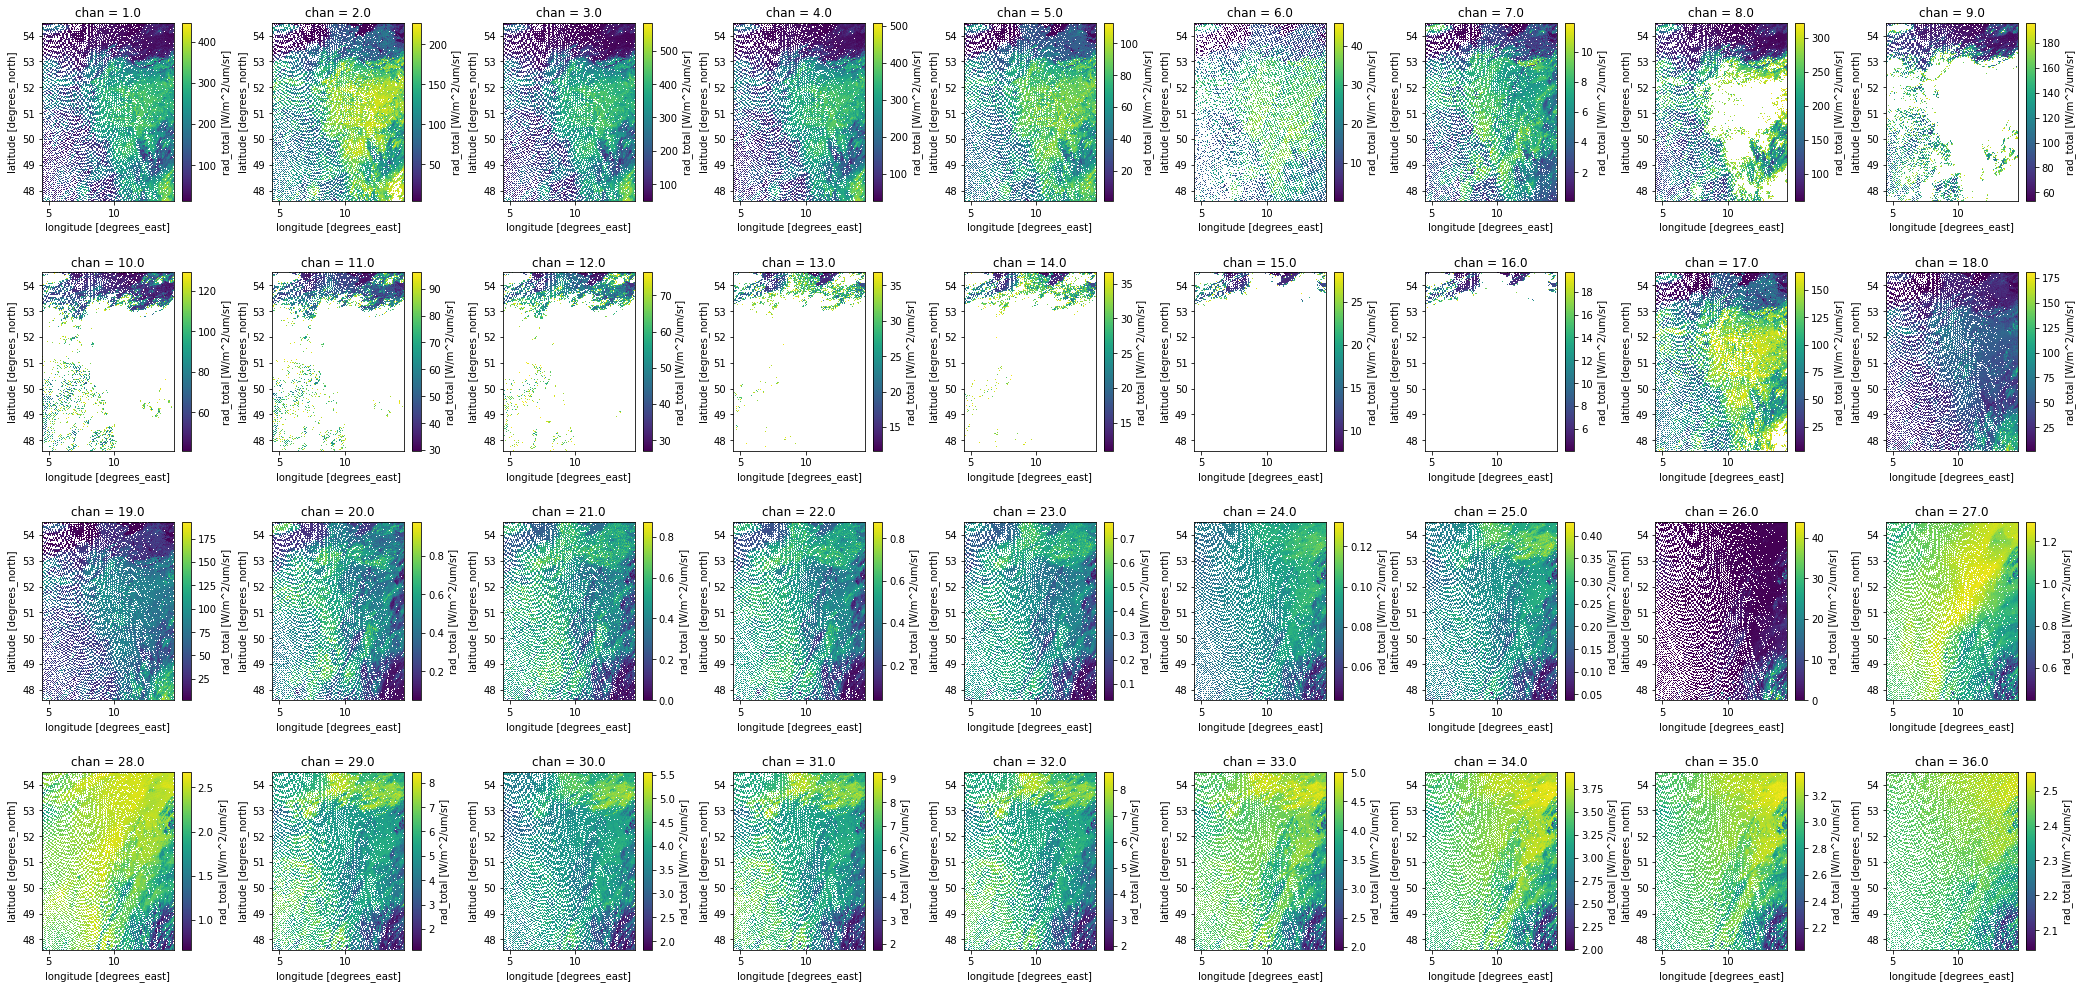

In [27]:
f, axes = plt.subplots(4,9,figsize=(4*9, 4*4*1.066)) #width of 15 inches and 7 inches in height.
f.subplots_adjust(wspace=0.4, hspace=0.4)
axli = axes.ravel()
for i in range(36):
    modis_ds["rad_total"][i].plot(cmap='viridis', ax = axli[i]) #, cmap='cividis'

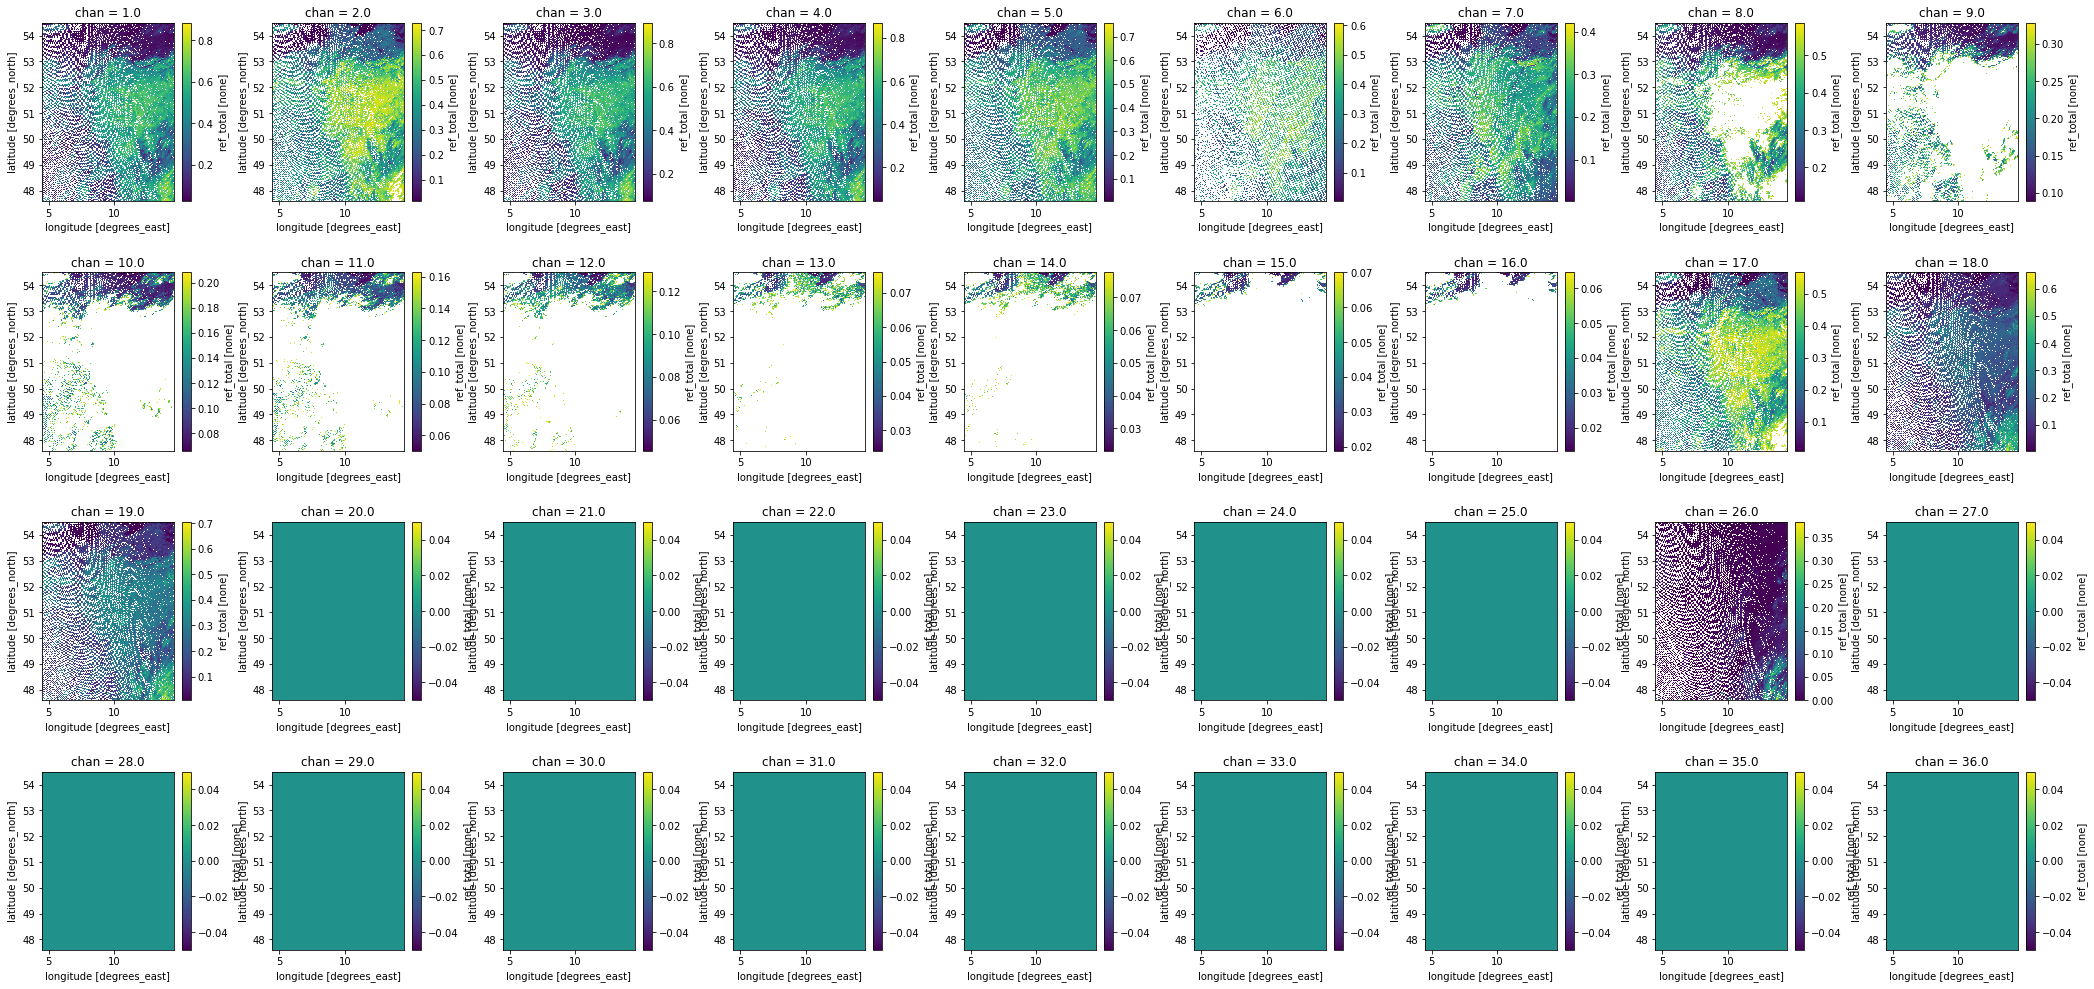

In [28]:
f, axes = plt.subplots(4,9,figsize=(4*9, 4*4*1.066)) #width of 15 inches and 7 inches in height.
f.subplots_adjust(wspace=0.4, hspace=0.4)
axli = axes.ravel()
for i in range(36):
    modis_ds["ref_total"][i].plot(cmap='viridis', ax = axli[i]) #, cmap='cividis

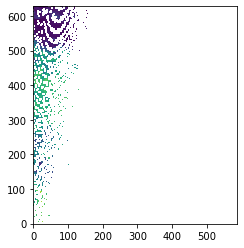

In [29]:
import numpy as np
plt.imshow(np.fliplr(modis_ds["ref_total"][0]),  origin='lower') 

In [30]:
print("values of nan in the x",np.isnan( modis_ds["ref_total"]).sum())   #.flatten()

values of nan in the x <xarray.DataArray 'ref_total' ()>
array(4231946)


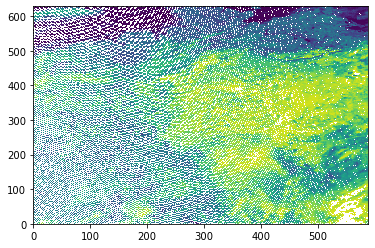

In [31]:
plt.pcolormesh(modis_ds["ref_total"][1])

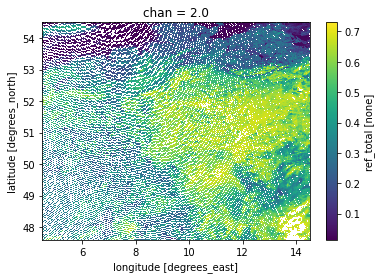

In [32]:
modis_ds["ref_total"][1].plot()

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


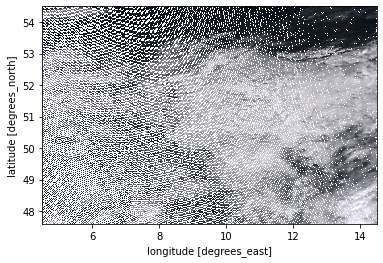

In [35]:
rgb_data = modis_ds['ref_total'][[0, 3, 2],...]/0.8
rgb_data.plot.imshow()

# variables used

In [14]:
import argparse
import glob
import os
import pprint
import sys
import numpy as np
import matplotlib.pyplot as plt
from pyhdf.SD import SD, SDC
import matplotlib.pyplot as plt
import pandas as pd

          
path_dataset = "/work/bb1036/b381362/dataset"
path_output = "/work/bb1036/b381362/output"
task = 'spectral' 
data_file = 'MYD021KM.A2013122.1140.061.2018046032403.hdf'
geolocation_file = 'MYD03.A2013122.1140.061.2018046005026.hdf'
print(" ********** MODIS level1B data **********")
file_data = SD(os.sep.join([path_dataset,data_file]), SDC.READ)
#dataset_dic(file_data)
#set the modis file L1 & geo
print(" ********** Geolocation file **********")
file_geo = SD(os.sep.join([path_dataset,geolocation_file]), SDC.READ)
#dataset_dic(file_geo)
#Selecting the area of Germany
map_boundaries=np.zeros(4)  ##
map_boundaries[0] = 47.599 #llcrnrlat
map_boundaries[1] = 54.5 #urcrnrlat
map_boundaries[2] = 4.5 #llcrnrlon
map_boundaries[3] = 14.5 #urcrnrlon
gridSize_lon=0.017 # 1 grado = 100 km => 0.01 grados = 1 km
gridSize_lat=0.011 # 1 grado = 100 km => 0.01 grados = 1 km

 ********** MODIS level1B data **********
 ********** Geolocation file **********


In [15]:
# import cartopy.crs as ccrs

# lat_m = np.nanmean(modis_ds.lat.values)
# lon_m = np.nanmean(modis_ds.lon.values)

# # Let's use ortho projection.
# orth = ccrs.Orthographic(central_longitude=lon_m,
#                          central_latitude=lat_m,
#                          globe=None)

# ax = plt.axes(projection=orth)

# plt.pcolormesh(modis_ds.lat, modis_ds.lon, modis_ds["ref_total"][0], transform=ccrs.PlateCarree())



In [30]:
#!ls /work/bb1036/b381362/dataset/